In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import os
import glob
import shutil
import geopandas as gpd

import xarray as xr
import numpy as np
#from pyhomogenize import open_xrdataset
import seaborn as sns
#
import matplotlib as mpl
import matplotlib.pyplot as plt
import cftime
import xesmf as xe
import cordex as cx

In [29]:
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure, colorsteps_comp_ev
from plotting_tools_africa import plot_absolut, plot_diff_compev
from plotting_shape_file import min_max_levels, mask_and_save, maskout_country, maskout_country_one
from regrid_afr22 import regrid_ensemble_median, regrid_ensemble
from calculate_diff_robustness import timeslice, ensemblemean_exp

In [4]:
# The data needs to be regridded to the AFR-22 domain.
# Target Grid::
dm=cx.cordex_domain('AFR-22', bounds=True)

### create annual files as input
the compound event script, does ot provide annual values, just sum per time slice, therefore the annual values need to calculated to later calculate the robustnes. Since this takes some time, it will be calculated with a slurm script, not within this Notebook.
Edit the following file to your needs:

    calculate_annual_ev_coin_du.py
 Load your environment and run with
 
    run_annual_ev_coin_du.sh


In [5]:
# Directory input data: calculated compound events
datadir='/work/ch0636/g300047/cicles/compound-events/results/annual_ev_coin_du'
outdatadir='/work/ch0636/g300047/cicles/compound-events/results/diff_robustness'

In [37]:
# Input shapefile:
# Admin regions
# select country and correct shape file
country='Burkina_Faso'
#short file name for Burkina Faso: 'BF'
country_short='BF'

adm_reg_dir='/work/ch0636/g300047/cicles/regions/WASCAL/WASCAL_Country'
admfiles = ['Togo.shp', "Côte d'Ivoire.shp",'Burkina Faso.shp']

# Select admit files
adm_shapefile =os.path.join(adm_reg_dir, admfiles[2])
shpfile_country=gpd.read_file(adm_shapefile)


In [50]:
# Make decision what you want to plot:
plot_options = {
	"SU40_du3_TR26_du3": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥3 days) and tropical nights (Tmin>26°C, ≥3 days)",
	"SU35_du3_DD_du5": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>35°C, ≥3 days) and dry days [RR<1mm/day, ≥5 days]",
	"SU35_du3_R20mm_du1": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>35°C, ≥3 days) and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_DD_du5": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥3 days) and dry days [RR<1mm/day, ≥5 days]",
	"SU40_du3_R20mm_du1": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥3 days) and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_TR_du3": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥3 days) and tropical nights [Tmin>20°C, ≥3 days]",
	"SU40_du3_R50mm_du1": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥3 days) and heavy precipitation events [RR>50mm/day, ≥1 day]",
	"SU35_du7_DD_du7": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>35°C, ≥7 days) and dry days [RR<1mm/day, ≥7 days]",
	"DD_du7_R20mm_du1": "Ensemble median differences to 1991-2020 for concurrent\ndry days [RR<1mm/day, ≥7 days] and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du7_DD_du7": "Ensemble median differences to 1991-2020 for concurrent\nheat days (Tmax>40°C, ≥7 days) and dry days [RR<1mm/day, ≥7 days]",
}
plot_options_absolute = {
	"SU40_du3_TR26_du3": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥3 days) and tropical nights (Tmin>26°C, ≥3 days)",
	"SU35_du3_DD_du5": "Ensemble median of concurrent\nheat days (Tmax>35°C, ≥3 days) and dry days [RR<1mm/day, ≥5 days]",
	"SU35_du3_R20mm_du1": "Ensemble median of concurrent\nheat days (Tmax>35°C, ≥3 days) and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_DD_du5": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥3 days) and dry days [RR<1mm/day, ≥5 days]",
	"SU40_du3_R20mm_du1": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥3 days) and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_TR_du3": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥3 days) and tropical nights [Tmin>20°C, ≥3 days]",
	"SU40_du3_R50mm_du1": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥3 days) and heavy precipitation events [RR>50mm/day, ≥1 day]",
	"SU35_du7_DD_du7": "Ensemble median of concurrent\nheat days (Tmax>35°C, ≥7 days) and dry days [RR<1mm/day, ≥7 days]",
	"DD_du7_R20mm_du1": "Ensemble median of concurrent\ndry days [RR<1mm/day, ≥7 days] and heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du7_DD_du7": "Ensemble median of concurrent\nheat days (Tmax>40°C, ≥7 days) and dry days [RR<1mm/day, ≥7 days]",
}

var_pattern = "SU40_du3_TR26_du3"
#var_pattern = "SU35_du3_DD_du5"
#var_pattern = "SU35_du3_R20mm_du1"
#var_pattern = "SU40_du3_DD_du5"
#var_pattern = "SU40_du3_R20mm_du1"
#var_pattern = "SU40_du3_TR_du3"
#var_pattern = "SU40_du3_R50mm_du1"
#var_pattern = "SU35_du7_DD_du7"
#var_pattern = "DD_du7_R20mm_du1"
#var_pattern = "SU40_du7_DD_du7"


if var_pattern not in plot_options:
	raise ValueError(f"Unknown var_pattern: {var_pattern}. Available: {list(plot_options.keys())}")

title = plot_options[var_pattern]
title_absolute = plot_options_absolute[var_pattern]
print(f"Selected var_pattern: {var_pattern}")

Selected var_pattern: SU40_du3_TR26_du3


### Common grid
Files need to be regridded to the common AFR22 grid. 
This is done outside this notebook, because of time intensive calculation. You need to edit 

    annual_regrid.py

The code is using *from regrid_afr22 import regrid_ensemble*

And send it as a slurm script with:

    sbatch run_annual_remap.sh

Results are in weights_dir=os.path.join(datadir,'weights')

Calculated outside this notebook with
    
    annual_diff_robust.py
    sbatch run_annual_robust.sh
It does the following:
* selects time slice, ('1991-2020','2031-2060', '2069-2098') 
which is set in calculate_diff_robustness import timeslice
* calculates the mean over the time slice, for each simulation

The function *ensemblemean_exp*
takes care of the calculation of
* ensemble mean , result: outdatadir/diff_robustness/ENS_MEAN(MEDIAN)*
* ensemble median 
* calculate the difference
* calculate the significance of change : outdatadir/significance*
This result file will contain:
* input value: ev_coin_du(time, rlat, rlon)float32
* mann white u test result: p_value(rlat, rlon)float32
* significance(rlat, rlon)int64
* ev_coin_du_diff(rlat, rlon)float32
Finaly the ENS_ROBUSTNESS* files will contain, the results for the whole ensemble


In [12]:
sims_rcp26 = glob.glob('/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_'+var_pattern+'*_rcp26.nc')
sims_rcp26.sort()
sims_rcp85 = glob.glob('/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_'+var_pattern+'*_rcp85.nc')
sims_rcp85.sort()

print(sims_rcp85, sims_rcp26)

['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp85.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp85.nc'] ['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp26.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp26.nc']


In [ ]:
# plot
plotdir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events'
# mean is also available instead of median, but median is more robust to outliers
var='ev_coin_du_days_ensemble_median_diff'
var2='robustness'
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_comp_ev(var,var_pattern)
datadir='/work/ch0636/g300047/cicles/compound-events/results/diff_robustness'

# mask out only country
#print(shpfile_country,
print(var) 
print(datadir)
sims_rcp26_masked, sims_rcp85_masked = maskout_country(
    sims_rcp26,
    sims_rcp85,
    shpfile_country,
    dm,
    var,
    var2,
    datadir,
    country_short
    )


Selected colors, levels for plotting  ev_coin_du_days_ensemble_median_diff
ev_coin_du_days_ensemble_median_diff
/work/ch0636/g300047/cicles/compound-events/results/diff_robustness
Masking ev_coin_du_days_ensemble_median_diff and robustness in /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp26.nc and saving to /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp26_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc
Masking ev_coin_du_days_ensemble_median_diff and robustness in /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp26.nc and saving to /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp26_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc
Masking ev_coin_du_days_ensemble_median_diff and robustn

['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp26_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp26_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc']
['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2031-2060_rcp85_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU40_du3_TR26_du3_2069-2098_rcp85_ev_coin_du_days_ensemble_median_diff_robustness_BF_masked.nc']
shapefile provided:
adding borders from shapefile
adding borders from shapefile
adding borders from shapefile
adding borders from shapefile
sims_rcp26 ['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED/ENS_ROBUSTNESS_SU4

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:1057: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.03, 0.01, 0.97, 0.99])


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/Compev_SU40_du3_TR26_du3_median_diff_Burkina_Faso_1200_oT.png


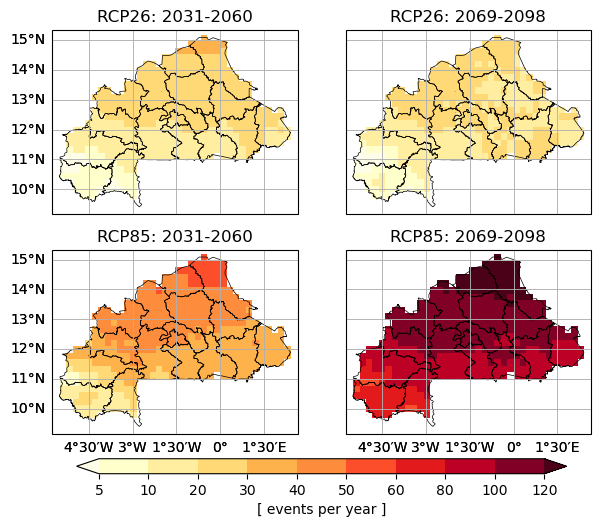

In [18]:
#level_steps = min_max_levels(sims_rcp26_masked, sims_rcp85_masked, var1)
color_steps, level_steps = colorsteps_comp_ev(var1, var_pattern)

plot_diff_compev(
    sims_rcp26_masked,
    sims_rcp85_masked,
    level_steps,
    color_steps,
    plotdir,
    title='',
    var=var,
    var_pattern=var_pattern,
    robustness=True,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=2,
    columns=2,
    fancy=None,
    
)

In [85]:
ls -ltr /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/


total 32040
-rw-r--r-- 1 g300047 ch0636 2423284 Dec  2  2025 SU40_du3_TR_du3_median_absolut_West_Africa_1200.png
-rw-r--r-- 1 g300047 ch0636 2360132 Dec  2  2025 SU40_du3_TR26_du3_median_absolut_West_Africa_1200.png
-rw-r--r-- 1 g300047 ch0636 2009814 Dec  2  2025 SU35_du3_R20mm_du1_median_absolut_West_Africa_1200.png
-rw-r--r-- 1 g300047 ch0636 2425855 Dec  2  2025 SU40_du3_DD_du5_median_absolut_West_Africa_1200.png
-rw-r--r-- 1 g300047 ch0636 2493317 Jan 30 10:20 SU35_du3_DD_du5_median_absolut_West_Africa_1200.png
-rw-r--r-- 1 g300047 ch0636 2502853 Feb  3 13:22 SU35_du3_DD_du5_median_absolut_1200.png
-rw-r--r-- 1 g300047 ch0636 2895866 Jun 25 11:55 SU35_du3_DD_du5_median_absolut_Burkina_Faso_1200.png
-rw-r--r-- 1 g300047 ch0636 2402900 Jun 25 12:21 ev_coin_sdu_median_absolut_1200.png
-rw-r--r-- 1 g300047 ch0636  426785 Jul 24 12:33 Compev_SU40_du3_DD_du5_median_diff_Burkina_Faso_300_oT.png
-rw-r--r-- 1 g300047 ch0636  559878 Jul 24 12:33 Compev_SU40_du3_DD_du5_median_diff_Burkina_Fa

In [86]:
ls -ltr /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR*GERICS-REMO2015_v1_day_GERICS_2069*


-rw-r--r-- 1 g300047 ch0636 442890163 Aug 11  2025 /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc
-rw-r--r-- 1 g300047 ch0636 523167074 Aug 11  2025 /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc
-rw-r--r-- 1 g300047 ch0636 428942939 Aug 11  2025 /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MPI-M-MPI-ESM-LR_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc
-rw-r--r-- 1 g300047 ch0636 555261107 Aug 11  2025 /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc
-rw-r--r-- 1 g300047 ch0636 436807828 Aug 11  2025 /work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_GERICS-REMO2015_v1

### Absolute:

In [23]:
#Vielleicht auch noch absolue plots sicherheits halber
file='/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR_du3_rcp85_2069-2098.nc'
dftest=xr.open_dataset(file, decode_times=False)
dftest

<xarray.Dataset> Size: 3MB
Dimensions:          (rlat: 402, rlon: 388)
Coordinates:
  * rlon             (rlon) float64 3kB -24.75 -24.53 -24.31 ... 60.17 60.39
  * rlat             (rlat) float64 3kB -45.87 -45.65 -45.43 ... 42.13 42.35
    lon              (rlat, rlon) float64 1MB ...
    lat              (rlat, rlon) float64 1MB ...
Data variables:
    ev_coin_du_days  (rlat, rlon) float32 624kB ...

In [ ]:
datadir

In [40]:
sims_rcp26 = glob.glob(datadir+'/ENS_MEDIAN_'+var_pattern+'_rcp26_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp26
sims_rcp85 = glob.glob(datadir+'/ENS_MEDIAN_'+var_pattern+'_rcp85_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp85.sort()
sims_rcp85

['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_1991-2020.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_2031-2060.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_2069-2098.nc']

In [42]:
# plot

plotdir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events'
# mean is also available instead of median, but median is more robust to outliers
var='ev_coin_du_days'
print('Selected colors, levels for plotting ', var_pattern)
color_steps, level_steps = colorsteps_comp_ev(var,var_pattern)
datadir='/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/'

# mask out only country
#print(shpfile_country,
print(var) 
print(datadir)
sims_rcp26_masked, sims_rcp85_masked = maskout_country_one(
    sims_rcp26,
    sims_rcp85,
    shpfile_country,
    dm,
    var,
    datadir,
    country_short)

Selected colors, levels for plotting  SU40_du3_TR26_du3
ev_coin_du_days
/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/
Masking ev_coin_du_days in /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_1991-2020.nc and saving to /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_1991-2020_ev_coin_du_days_BF_masked.nc
Masking ev_coin_du_days in /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_2031-2060.nc and saving to /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_2031-2060_ev_coin_du_days_BF_masked.nc
Masking ev_coin_du_days in /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_2069-2098.nc and saving to /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASK

In [45]:
level_steps = min_max_levels(sims_rcp26_masked, sims_rcp85_masked, var)

['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_1991-2020_ev_coin_du_days_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_2031-2060_ev_coin_du_days_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp26_2069-2098_ev_coin_du_days_BF_masked.nc']
['/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_1991-2020_ev_coin_du_days_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_2031-2060_ev_coin_du_days_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/diff_robustness/MASKED_ABSOLUTE/ENS_MEDIAN_SU40_du3_TR26_du3_rcp85_2069-2098_ev_coin_du_days_BF_masked.nc']
shapefile provided:
adding borde

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:612: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU40_du3_TR26_du3_absolut_Burkina_Faso_1200.png


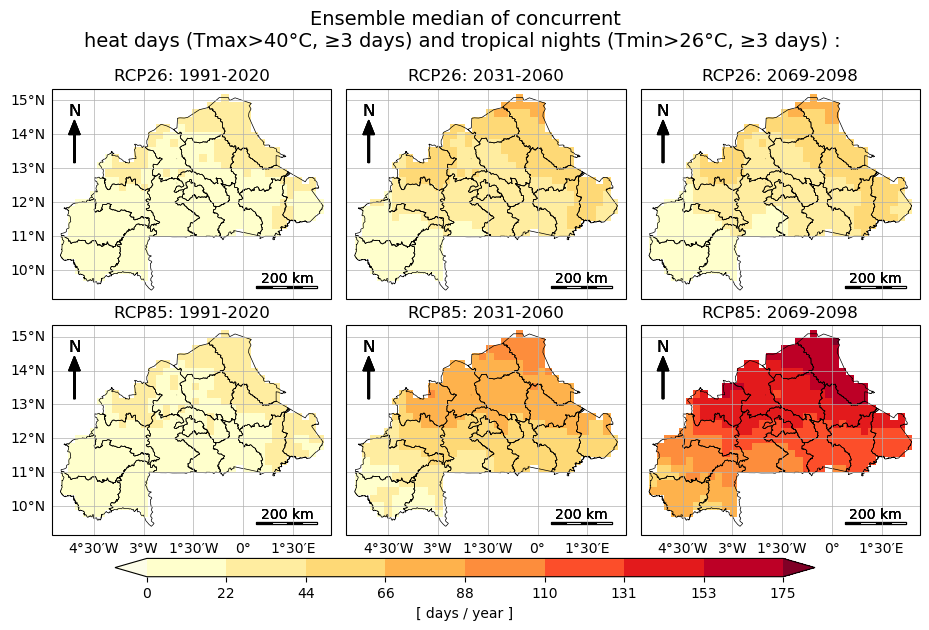

In [51]:
# Restore the plotting box using the existing variables and plot_absolut
plot_absolut(
    sims_rcp26_masked,
    sims_rcp85_masked,
    level_steps,
    color_steps,
    plotdir,
    title=title_absolute,
    var='ev_coin_du_days',
    var_pattern=var_pattern,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=2,
    columns=3,
    fancy=True,
    row_gap=-0.05,
    wspace=0.25
)

### Testing plot features

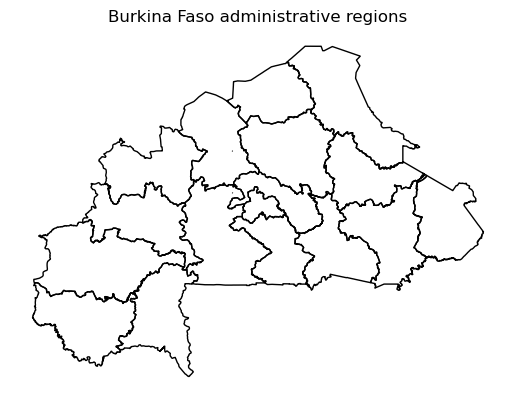

In [ ]:
# Plot the preloaded Burkina Faso shapefile
ax = shpfile_BF.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
ax.set_axis_off()
plt.show()

In [ ]:
# Add a dynamic scale bar (in km) to the existing shapefile plot (ax)

def _nice_length_km(target_km):
    # pick a nice rounded length close to 20% of map width
    candidates = [10, 25, 50, 100, 150, 200, 300, 500, 1000]
    for c in candidates:
        if c >= target_km:
            return c
    return candidates[-1]

def add_scalebar(ax, geom=None, location='lower left', segments=4, pad_frac=0.05, height_frac=0.01, font_size=10):
    # Representative latitude for km-per-degree conversion
    if geom is not None:
        lat_ref = float(geom.centroid.y)
    else:
        y0, y1 = ax.get_ylim()
        lat_ref = (y0 + y1) / 2.0

    # Approx km per degree of longitude at given latitude
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_ref))

    # Determine bar length ~ 20% of map width, rounded to a nice value
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    width_deg = x1 - x0
    width_km = max(1e-6, width_deg * km_per_deg_lon)
    length_km = _nice_length_km(width_km * 0.2)
    length_deg = length_km / km_per_deg_lon

    # Bar placement
    pad_x = pad_frac * width_deg
    pad_y = pad_frac * (y1 - y0)
    bar_height = height_frac * (y1 - y0)

    if location == 'lower left':
        bx0 = x0 + pad_x
        by0 = y0 + pad_y
    elif location == 'lower right':
        bx0 = x1 - pad_x - length_deg
        by0 = y0 + pad_y
    elif location == 'upper left':
        bx0 = x0 + pad_x
        by0 = y1 - pad_y - bar_height
    elif location == 'upper right':
        bx0 = x1 - pad_x - length_deg
        by0 = y1 - pad_y - bar_height
    else:
        bx0 = x0 + pad_x
        by0 = y0 + pad_y

    # Draw alternating black/white segments
    seg_width = length_deg / max(1, segments)
    for i in range(segments):
        rect = mpl.patches.Rectangle(
            (bx0 + i * seg_width, by0),
            seg_width,
            bar_height,
            facecolor=('black' if i % 2 == 0 else 'white'),
            edgecolor='black',
            linewidth=0.8
        )
        ax.add_patch(rect)

    # Label
    ax.text(
        bx0 + length_deg / 2.0,
        by0 + bar_height * 1.5,
        f'{int(length_km)} km',
        ha='center', va='bottom',
        fontsize=font_size
    )

# Compute Burkina Faso union geometry from the already loaded shapefile
union_geom = shpfile_BF.geometry.unary_union

# Use the existing ax and Burkina Faso geometry union to add a scale bar
add_scalebar(ax, geom=union_geom, location='lower left', segments=4)

/tmp/ipykernel_72054/775770534.py:74: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  union_geom = shpfile_BF.geometry.unary_union


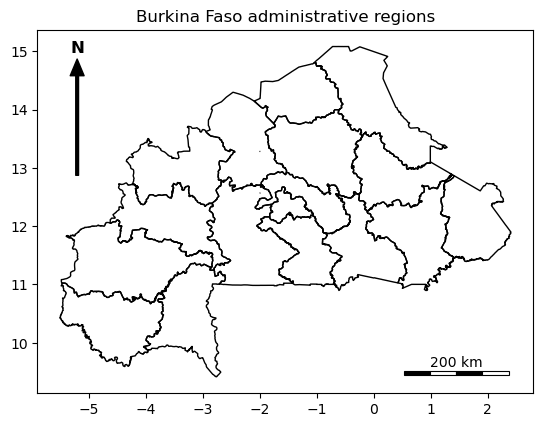

In [ ]:
ax = shpfile_BF.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
# Add a North arrow to the existing shapefile plot (ax)
arrowprops = dict(facecolor='black', edgecolor='black', width=2, headwidth=10, headlength=12)
# Arrow pointing up in axes coordinates
ax.annotate('', xy=(0.08, 0.92), xytext=(0.08, 0.60), xycoords='axes fraction', arrowprops=arrowprops)
# Label "N" above the arrow
ax.text(0.08, 0.93, 'N', transform=ax.transAxes, ha='center', va='bottom', fontsize=12, fontweight='bold')
add_scalebar(ax, geom=union_geom, location='lower right', segments=4)
plt.show()

## JUST TESTING:

In [ ]:
odir='/work/ch0636/g300047/cicles/compound-events/results/'
ifile='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'
#ifile='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098_regridded_AFR22.nc'
oldifile=os.path.join(odir, ifile)  
olddf=xr.open_dataset(oldifile, decode_times=False)
old_var = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf.data_vars else list(olddf.data_vars)[0]
extent = [-25, 20, -0.75, 27.3]
value35 = olddf[old_var] / 30

fig, ax = plt.subplots(figsize=(8, 6))
value35.plot(ax=ax)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
#plt.show()


In [ ]:
odir='/work/ch0636/g300047/cicles/compound-events/results/'

ifile35='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'
ifile40='compev_SU40_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'

oldifile35=os.path.join(odir, ifile35)
oldifile40=os.path.join(odir, ifile40)

olddf35=xr.open_dataset(oldifile35, decode_times=False)
olddf40=xr.open_dataset(oldifile40, decode_times=False)

old_var35 = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf35.data_vars else list(olddf35.data_vars)[0]
old_var40 = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf40.data_vars else list(olddf40.data_vars)[0]

extent = [-25, 20, -0.75, 27.3]
value35 = olddf35[old_var35] / 30
value40 = olddf40[old_var40] / 30

# Align on the common grid before subtraction to avoid coordinate mismatch issues
levels = np.arange(0, 100, 10)
value35, value40 = xr.align(value35, value40, join='override')
neu = value35 - value40

fig, ax = plt.subplots(figsize=(8, 6))
neu.plot(ax=ax, levels=levels, cmap='RdBu_r', cbar_kwargs={'label': 'Difference (days)'})
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

plt.show()

In [ ]:
# prüfe of new und alt übereinstimmen, also annual ev_coin_du und ev_coin_sdu

odir='/work/ch0636/g300047/cicles/compound-events/results/'

ifile35='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'
ndir='/work/ch0636/g300047/cicles/compound-events/results/annual_ev_coin_du'
nifile35='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098_annual.nc'

oldifile35=os.path.join(odir, ifile35)
nifile35=os.path.join(ndir, nifile35)

olddf35=xr.open_dataset(oldifile35, decode_times=False)
ndf35=xr.open_dataset(nifile35, decode_times=False)

old_var35 = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf35.data_vars else list(olddf35.data_vars)[0]
new_var35 = 'ev_coin_du' if 'ev_coin_du' in ndf35.data_vars else list(ndf35.data_vars)[0]

extent = [-25, 20, -0.75, 27.3]
value35 = olddf35[old_var35] / 30
new_value35 = ndf35[new_var35].mean(dim='time')  # Assuming you want the mean over time for the annual data

# Align on the common grid before subtraction to avoid coordinate mismatch issues
levels = np.arange(0, 300, 1)
value35, new_value35 = xr.align(value35, new_value35, join='override')
#neu = value35 #- 
neu=new_value35

fig, ax = plt.subplots(figsize=(8, 6))
neu.plot(ax=ax, levels=levels, cmap='RdBu_r', cbar_kwargs={'label': 'Difference (days)'})
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

plt.show()

# Ja stimmen über ein

In [ ]:
# jetzt die Änderung prüfen, 
odir='/work/ch0636/g300047/cicles/compound-events/results/'

ifile35='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'
ifile40='compev_SU40_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc'
hifile35='compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc'
hifile40='compev_SU40_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc'
oldifile35=os.path.join(odir, ifile35)
oldifile40=os.path.join(odir, ifile40)
hifile35=os.path.join(odir, hifile35)
hifile40=os.path.join(odir, hifile40)

olddf35=xr.open_dataset(oldifile35, decode_times=False)
olddf40=xr.open_dataset(oldifile40, decode_times=False)
hidf35=xr.open_dataset(hifile35, decode_times=False)
hidf40=xr.open_dataset(hifile40, decode_times=False)

old_var35 = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf35.data_vars else list(olddf35.data_vars)[0]
old_var40 = 'ev_coin_sdu' if 'ev_coin_sdu' in olddf40.data_vars else list(olddf40.data_vars)[0]

extent = [-25, 20, -0.75, 27.3]
value35 = (olddf35[old_var35] - hidf35[old_var35]) / 30
value40 = (olddf40[old_var40] - hidf40[old_var40]) / 30
# Align on the common grid before subtraction to avoid coordinate mismatch issues
levels = np.arange(0, 100, 10)
value35, value40 = xr.align(value35, value40, join='override')
neu = value40 - value35

fig, ax = plt.subplots(figsize=(8, 6))
neu.plot(ax=ax, levels=levels, cmap='RdBu_r', cbar_kwargs={'label': 'Difference (days)'})
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

plt.show()